# Week1_ex3 Analysis — Constant-Impedance vs Constant-Q Capacitor Models

Deep dive on Example 2.3 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.). A capacitor bank rated $Q_{rated}$ at 1.0 pu can be modeled in pandapower in two ways, and both converge without complaint:

$$\text{H1 (constant Q, } \texttt{create\_sgen}\text{): } Q_C = Q_{rated} \qquad \text{H2 (constant Z, } \texttt{create\_shunt}\text{): } Q_C = Q_{rated}\,V^2$$

At nominal voltage the two are identical. Below it, H1 keeps injecting the full rating while H2 loses output with the square of the voltage, so they should drift apart exactly in the low-voltage operating region a heat-wave or N-1 study cares about. PowerWorld's 80 kvar bank on the lossy line, where the load bus sags to 14.97 kV, decides which model the pipeline should use.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandapower as pp
from pandapower.powerflow import LoadflowNotConverged

# 1. Case data read once from PowerWorld Simulator (Run Mode, Model Explorer > Network; Simulator Options)
S_BASE_KVA = 100.0
V_BASE_KV = 16.0
Z_BASE_OHM = V_BASE_KV**2 / (S_BASE_KVA / 1000)
R_PU, X_PU = 0.05, 0.10                 # "Line Including Losses"
LOAD_KW, LOAD_KVAR = 100.10, 75.08
CAP_STEP_KVAR = 20.0
KVA_TOL = 0.1


def build_case(cap_kvar, model, load_scale=1.0):
    net = pp.create_empty_network(f_hz=60, sn_mva=S_BASE_KVA / 1000)
    bus_a = pp.create_bus(net, V_BASE_KV, name="Bus A")
    bus_b = pp.create_bus(net, V_BASE_KV, name="Load Bus")
    pp.create_ext_grid(net, bus_a, vm_pu=1.0)
    pp.create_line_from_parameters(net, bus_a, bus_b, length_km=1.0, r_ohm_per_km=R_PU * Z_BASE_OHM,
                                   x_ohm_per_km=X_PU * Z_BASE_OHM, c_nf_per_km=0.0, max_i_ka=1.0)
    pp.create_load(net, bus_b, p_mw=LOAD_KW / 1000 * load_scale, q_mvar=LOAD_KVAR / 1000 * load_scale)
    if model == "H1":
        # sgen uses the generator sign convention: positive q_mvar is injected into the bus
        pp.create_sgen(net, bus_b, p_mw=0.0, q_mvar=cap_kvar / 1000, name="Capacitor (constant Q)")
    else:
        # shunt uses the load sign convention and a rating at 1.0 pu: negative q_mvar is a capacitor
        pp.create_shunt(net, bus_b, q_mvar=-CAP_STEP_KVAR / 1000, step=int(cap_kvar // CAP_STEP_KVAR),
                        max_step=10, name="Capacitor (constant Z)")
    pp.runpp(net, numba=False)
    return net


def cap_output_kvar(net):
    return net.res_sgen.q_mvar.sum() * 1000 if len(net.sgen) else -net.res_shunt.q_mvar.sum() * 1000


pd.DataFrame({
    "Model": ["H1: constant Q", "H2: constant Z"],
    "pandapower element": ["create_sgen(q_mvar=+0.08)", "create_shunt(q_mvar=-0.02, step=4)"],
    "Sign convention": ["generator (+ = injected)", "load (+ = consumed)"],
    "Output at 1.0 pu [kvar]": [80.0, 80.0],
})

,Model,pandapower element,Sign convention,Output at 1.0 pu [kvar]
0,H1: constant Q,create_sgen(q_mvar=+0.08),generator (+ = injected),80.0
1,H2: constant Z,"create_shunt(q_mvar=-0.02, step=4)",load (+ = consumed),80.0


In [2]:
# 2. Measured: PowerWorld, lossy line, read once from the one-line (Run Mode)
pw = {80: {"Load Bus voltage [kV]": 14.97, "Capacitor output [kvar]": 70.0, "Line P loss [kW]": 5.73},
      100: {"Capacitor output [kvar]": 92.0}}
tol = {"Load Bus voltage [kV]": 5e-3, "Capacitor output [kvar]": 0.05, "Line P loss [kW]": KVA_TOL}
tol_100 = 0.5   # the 100 kvar reading was shown as a whole number

rows = []
for cap, values in pw.items():
    for model in ("H1", "H2"):
        net = build_case(cap, model)
        pp_vals = {"Load Bus voltage [kV]": net.res_bus.vm_pu.iat[1] * V_BASE_KV,
                   "Capacitor output [kvar]": cap_output_kvar(net),
                   "Line P loss [kW]": net.res_line.pl_mw.iat[0] * 1000}
        for qty, pw_val in values.items():
            t = tol_100 if cap == 100 else tol[qty]
            rows.append({"Bank [kvar]": cap, "Model": model, "Quantity": qty, "PowerWorld": pw_val,
                         "pandapower": pp_vals[qty], "Tolerance": t})
cmp = pd.DataFrame(rows)
cmp["Abs error"] = (cmp["pandapower"] - cmp["PowerWorld"]).abs()
cmp["Within"] = cmp["Abs error"] <= cmp["Tolerance"]
assert cmp.loc[cmp.Model == "H2", "Within"].all() and not cmp.loc[cmp.Model == "H1", "Within"].any()
cmp.round(3)

,Bank [kvar],Model,Quantity,PowerWorld,pandapower,Tolerance,Abs error,Within
0,80,H1,Load Bus voltage [kV],14.97,15.143,0.005,0.173,False
1,80,H1,Capacitor output [kvar],70.00,80.000,0.050,10.000,False
2,80,H1,Line P loss [kW],5.73,5.607,0.100,0.123,False
3,80,H2,Load Bus voltage [kV],14.97,14.971,0.005,0.001,True
4,80,H2,Capacitor output [kvar],70.00,70.038,0.050,0.038,True
5,80,H2,Line P loss [kW],5.73,5.737,0.100,0.007,True
6,100,H1,Capacitor output [kvar],92.00,100.000,0.500,8.000,False
7,100,H2,Capacitor output [kvar],92.00,91.967,0.500,0.033,True


## Hypothesis 1 — a capacitor bank is a fixed reactive power injection

If PowerWorld treated the bank as a constant 80 kvar source, the bank would read 80 kvar on the lossy line and the load bus would settle where a full 80 kvar of support puts it.

**Verdict: rejected.** PowerWorld reports 70.0 kvar from the 80 kvar bank and 92 kvar from the 100 kvar bank, and none of the four H1 readings lands within tolerance: the extra 10 kvar of phantom support lifts the load bus to 15.14 kV instead of 14.97 kV and trims the line loss by about 0.13 kW.

## Hypothesis 2 — a capacitor bank is a constant admittance

If the bank is a fixed susceptance, its output is the rating times $V^2$: $80 \times 0.9357^2 = 70.0$ kvar and $100 \times 0.959^2 = 92.0$ kvar.

**Verdict: accepted.** All four H2 readings match PowerWorld within tolerance, including the 70.0 kvar figure to 0.04 kvar and the load bus voltage to 0.001 kV.

In [3]:
# 3. Stress test: scale the load up until the power flow stops converging, with the 80 kvar bank in place
def load_bus_voltage(scale, model):
    try:
        return build_case(80, model, scale).res_bus.vm_pu.iat[1]
    except LoadflowNotConverged:
        return np.nan


def collapse_scale(model, lo=1.0, hi=5.0, tol=1e-4):
    while hi - lo > tol:
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if np.isfinite(load_bus_voltage(mid, model)) else (lo, mid)
    return lo


limit = {m: collapse_scale(m) for m in ("H1", "H2")}
scales = np.round(np.arange(1.0, limit["H1"], 0.05), 2)
pv = pd.DataFrame({"Load scale": scales,
                   "H1 voltage [pu]": [load_bus_voltage(s, "H1") for s in scales],
                   "H2 voltage [pu]": [load_bus_voltage(s, "H2") for s in scales]})
pv["Voltage gap [pu]"] = pv["H1 voltage [pu]"] - pv["H2 voltage [pu]"]

pd.DataFrame({
    "Model": ["H1: constant Q", "H2: constant Z"],
    "Last converged load scale": [limit["H1"], limit["H2"]],
    "Load at that point [kW]": [LOAD_KW * limit["H1"], LOAD_KW * limit["H2"]],
    "Margin vs H2 [%]": [(limit["H1"] / limit["H2"] - 1) * 100, 0.0],
}).round(3)

,Model,Last converged load scale,Load at that point [kW],Margin vs H2 [%]
0,H1: constant Q,2.356,235.880,16.153
1,H2: constant Z,2.029,203.078,0.000


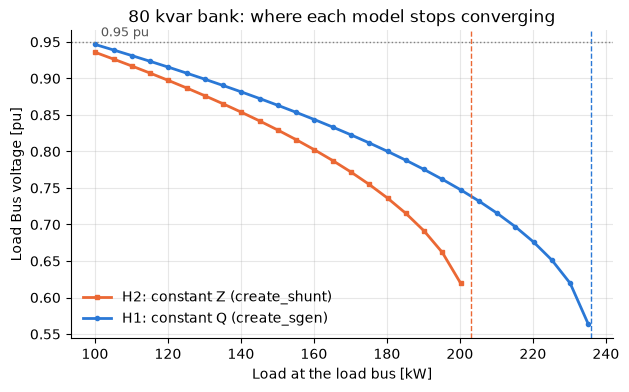

In [4]:
# 4. Plot the load bus voltage under both models as the load grows
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pv["Load scale"] * LOAD_KW, pv["H2 voltage [pu]"], color="#eb6834", lw=2, marker="s", ms=3,
        label="H2: constant Z (create_shunt)")
ax.plot(pv["Load scale"] * LOAD_KW, pv["H1 voltage [pu]"], color="#2a78d6", lw=2, marker="o", ms=3,
        label="H1: constant Q (create_sgen)")
for model, color in [("H2", "#eb6834"), ("H1", "#2a78d6")]:
    ax.axvline(limit[model] * LOAD_KW, color=color, ls="--", lw=1)
ax.axhline(0.95, color="gray", ls=":", lw=1)
ax.annotate("0.95 pu", (pv["Load scale"].iat[0] * LOAD_KW, 0.95), textcoords="offset points",
            xytext=(4, 4), fontsize=9, color="#555555")
ax.set_xlabel("Load at the load bus [kW]")
ax.set_ylabel("Load Bus voltage [pu]")
ax.set_title("80 kvar bank: where each model stops converging")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.savefig("Images/Week1_ex3_capacitor_model_pv_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# 5. Gap between the two models at a few load levels
pv.iloc[np.searchsorted(pv["Load scale"].values, [1.0, 1.25, 1.5, 1.75, 2.0])].assign(
    **{"Load [kW]": lambda d: d["Load scale"] * LOAD_KW}
)[["Load scale", "Load [kW]", "H2 voltage [pu]", "H1 voltage [pu]", "Voltage gap [pu]"]].round(4).reset_index(drop=True)

,Load scale,Load [kW],H2 voltage [pu],H1 voltage [pu],Voltage gap [pu]
0,1.00,100.100,0.9357,0.9464,0.0108
1,1.25,125.125,0.8869,0.9073,0.0203
2,1.50,150.150,0.8292,0.8631,0.0339
3,1.75,175.175,0.7548,0.8117,0.0569
4,2.00,200.200,0.6197,0.7475,0.1278


## Final conclusion

PowerWorld models a capacitor bank as a constant admittance, so its output falls with the square of the bus voltage: the 80 kvar bank delivers 70.0 kvar at 0.936 pu, exactly as H2 predicts and H1 cannot. The modelling choice barely matters at nominal load, where the two readings sit about 0.01 pu apart, but it matters a great deal near the limit. A constant-Q bank keeps propping the voltage up as it sags, so H1 reports the load bus 0.13 pu higher at twice the base load and keeps converging for 16 % more load than the physically correct model. A voltage-stability margin built on that is optimistic by the same 16 %, in precisely the heat-wave and N-1 cases the pipeline is meant to stress. The pipeline therefore models every capacitor bank with `create_shunt` (negative `q_mvar`, rated at 1.0 pu, actual output read from `res_shunt`), and never with a fixed-Q `sgen`.